In [148]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from statsmodels.multivariate.factor import Factor
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.stats import iqr as count_iqr
from sklearn.cluster import AgglomerativeClustering
from factor_analyzer.factor_analyzer import calculate_kmo
from factor_analyzer.factor_analyzer import calculate_bartlett_sphericity

In [140]:
df = pd.read_excel("data.xlsx", sheet_name = 2)
df.columns = ["regions", "pollutions", "fresh_water", "waste_water", "people_per_doctor", "grp_per_person"]
df = df.set_index("regions")
df.head()

,pollutions,fresh_water,waste_water,people_per_doctor,grp_per_person
regions,,,,,
Белгородская область,158,232,59.0,234.1,859545.1
Брянская область,54,89,52.0,258.5,474159.6
Владимирская область,73,120,91.0,264.2,585131.4
Воронежская область,115,399,121.0,186.2,600596.0
Ивановская область,25,94,58.0,212.3,395919.8


In [141]:
corr = df.corr().round(3)
corr.style.background_gradient()

,pollutions,fresh_water,waste_water,people_per_doctor,grp_per_person
pollutions,1.000000,0.490000,0.246000,-0.065000,0.356000
fresh_water,0.490000,1.000000,0.466000,0.062000,0.241000
waste_water,0.246000,0.466000,1.000000,-0.221000,0.257000
people_per_doctor,-0.065000,0.062000,-0.221000,1.000000,-0.525000
grp_per_person,0.356000,0.241000,0.257000,-0.525000,1.000000


In [167]:
df.corr().round(3).to_excel("corr.xlsx")

In [166]:
ylabels = ["тыс. т.", "млн. куб. м.", "млн. куб. м.", "чел.", "руб."]
i = 0

for column in df.columns:
    plt.figure(figsize = (8, 4))
    df.boxplot(column = [column])
    plt.ylabel(ylabels[i])
    plt.savefig(f"{i}s.png")
    plt.close()
    i += 1

In [163]:
iqrs = []
maxes = []
mines = []
desc_stat = df.describe()
desc_stat = desc_stat.T

for column in df.columns:
    iqrs.append(count_iqr(df[column].values))
    print(df[df[column] == df[column].max()].index[0])
    maxes.append(df[df[column] == df[column].max()].index[0])
    mines.append(df[df[column] == df[column].min()].index[0])

desc_stat["iqr"] = iqrs
desc_stat["var"] = desc_stat["max"] - desc_stat["min"]
desc_stat["min_region"] = mines
desc_stat["max_region"] = maxes

desc_stat.round(1)

Красноярский край
Ленинградская область
г. Санкт-Петербург
Курганская область
Тюменская область


,count,mean,std,min,25%,50%,75%,max,iqr,var,min_region,max_region
pollutions,82.0,209.5,423.7,2.0,33.5,95.5,197.2,2632.0,163.8,2630.0,Республика Ингушетия,Красноярский край
fresh_water,82.0,583.8,777.7,7.0,111.2,217.5,645.8,3539.0,534.5,3532.0,Республика Алтай,Ленинградская область
waste_water,82.0,138.1,185.4,0.0,31.2,75.5,158.0,933.0,126.8,933.0,Чеченская Республика,г. Санкт-Петербург
people_per_doctor,82.0,211.5,39.8,112.2,185.3,209.9,233.6,323.8,48.2,211.6,г. Санкт-Петербург,Курганская область
grp_per_person,82.0,803670.5,644698.3,159603.5,461610.8,621978.6,827317.8,3637116.5,365707.0,3477513.0,Республика Ингушетия,Тюменская область


In [164]:
desc_stat.to_excel("desctipt.xlsx")

In [80]:
std_df = df.copy()

for col in std_df.columns:
    std_df[col] = (std_df[col] - std_df[col].mean()) / std_df[col].std()

std_df.head()

,pollutions_per_area,fresh_water_per_area,waste_water_per_area,people_per_doctor,grp_per_person
regions,,,,,
Белгородская область,-0.121490,-0.452372,-0.426795,0.567965,0.086668
Брянская область,-0.366944,-0.636237,-0.464549,1.181365,-0.511109
Владимирская область,-0.322102,-0.596378,-0.254209,1.324659,-0.338979
Воронежская область,-0.222976,-0.237648,-0.092410,-0.636209,-0.314991
Ивановская область,-0.435388,-0.629808,-0.432189,0.019928,-0.632467


In [81]:
chi_square_value, p_value = calculate_bartlett_sphericity(std_df)
chi_square_value, p_value

(88.31789790229817, 1.1536940016884917e-14)

In [82]:
kmo_all, kmo_model = calculate_kmo(std_df)
kmo_model

0.5664305710915436

In [83]:
fa = Factor(std_df[std_df.columns], n_factor = 2, method = "pa")
res = fa.fit()

In [84]:
res.rotate(method = "varimax")
res.get_loadings_frame(threshold=0)

,factor 0,factor 1
fresh_water_per_area,1.010796,0.031786
pollutions_per_area,0.489133,0.231391
waste_water_per_area,0.424173,0.278643
people_per_doctor,0.093040,-0.743776
grp_per_person,0.230038,0.739039


In [168]:
ev = res.eigenvals

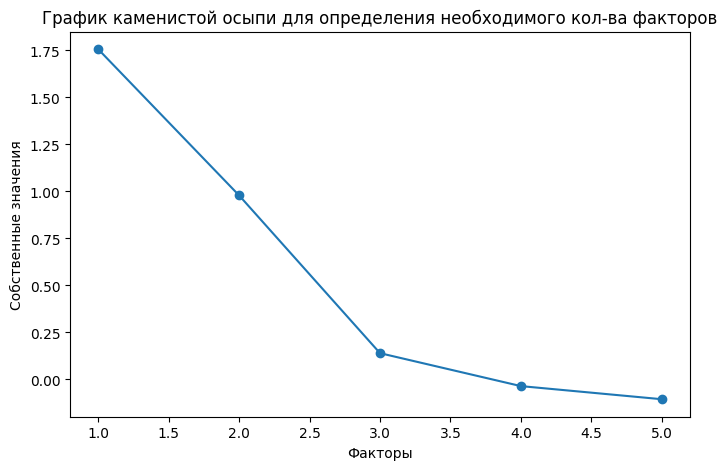

In [169]:
plt.close()

plt.figure(figsize=(8, 5))
plt.scatter(range(1,std_df.shape[1]+1),ev)
plt.plot(range(1,std_df.shape[1]+1),ev)
plt.title('График каменистой осыпи для определения необходимого кол-ва факторов')
plt.xlabel('Факторы')
plt.ylabel('Собственные значения')

plt.savefig("stones.png")

In [85]:
res.summary()

<class 'statsmodels.iolib.summary2.Summary'>
"""
                                    Factor analysis results
===============================================================================================
                            Eigenvalues                                                        
-----------------------------------------------------------------------------------------------
 pollutions_per_area fresh_water_per_area waste_water_per_area people_per_doctor grp_per_person
-----------------------------------------------------------------------------------------------
              1.7557               0.9783               0.1396           -0.0355        -0.1052
-----------------------------------------------------------------------------------------------
                                                                                               
-----------------------------------------------------------------------------------------------
                            Communality                                                        
-----------------------------------------------------------------------------------------------
 pollutions_per_area fresh_water_per_area waste_water_per_area people_per_doctor grp_per_person
-----------------------------------------------------------------------------------------------
              0.2928               1.0227               0.2576            0.5619         0.5991
-----------------------------------------------------------------------------------------------
                                                                                               
-----------------------------------------------------------------------------------------------
                         Pre-rotated loadings                                                  
--------------------------------------------------------------------------------------------------------------------------------------------------------
                                                                              factor 0                                                          factor 1
--------------------------------------------------------------------------------------------------------------------------------------------------------
pollutions_per_area                                                             0.5337                                                           -0.0892
fresh_water_per_area                                                            0.8481                                                           -0.5508
waste_water_per_area                                                            0.5073                                                           -0.0133
people_per_doctor                                                              -0.3481                                                           -0.6638
grp_per_person                                                                  0.6107                                                            0.4755
-----------------------------------------------------------------------------------------------
                                                                                               
-----------------------------------------------------------------------------------------------
                         varimax rotated loadings                                              
--------------------------------------------------------------------------------------------------------------------------------------------------------
                                                                              factor 0                                                          factor 1
--------------------------------------------------------------------------------------------------------------------------------------------------------
pollutions_per_area                                                             0.4891          

In [171]:
pd.DataFrame(res.loadings).to_excel("loadings.xlsx")

In [86]:
pces = np.dot(std_df, res.loadings)
pc1 = []
pc2 = []

for i in pces:
    print
    pc1.append(i[0])
    pc2.append(i[1])

In [87]:
data = {"regions": std_df.index, "PC1": pc1, "PC2": pc2}

integral_char = pd.DataFrame(data)
integral_char = integral_char.set_index("regions")
integral_char.head()

,PC1,PC2
regions,,
Белгородская область,-0.624934,-0.519802
Брянская область,-1.027299,-1.490974
Владимирская область,-0.822927,-1.400089
Воронежская область,-0.520129,0.155508
Ивановская область,-1.176530,-0.723430


In [88]:
integral_char.sort_values(by = "PC1", ascending=True).head()

,PC1,PC2
regions,,
Республика Тыва,-1.454612,-0.562958
Республика Алтай,-1.419929,-0.838443
Республика Мордовия,-1.378339,-0.202613
Республика Ингушетия,-1.377480,-1.262387
г. Севастополь,-1.318612,-0.910471


In [174]:
sk_ac = AgglomerativeClustering(n_clusters=3, linkage='ward')
sk_ac_pred_res = sk_ac.fit_predict(integral_char)

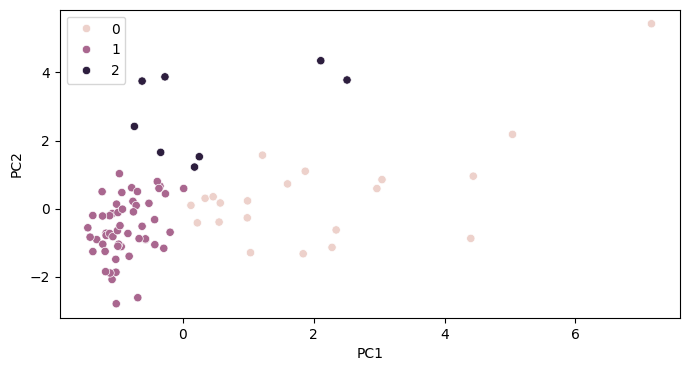

In [177]:
plt.close()
plt.figure(figsize=(8,4))
sns.scatterplot(data = integral_char, x = "PC1", y = "PC2", hue = sk_ac_pred_res)
plt.savefig("scatter.png")

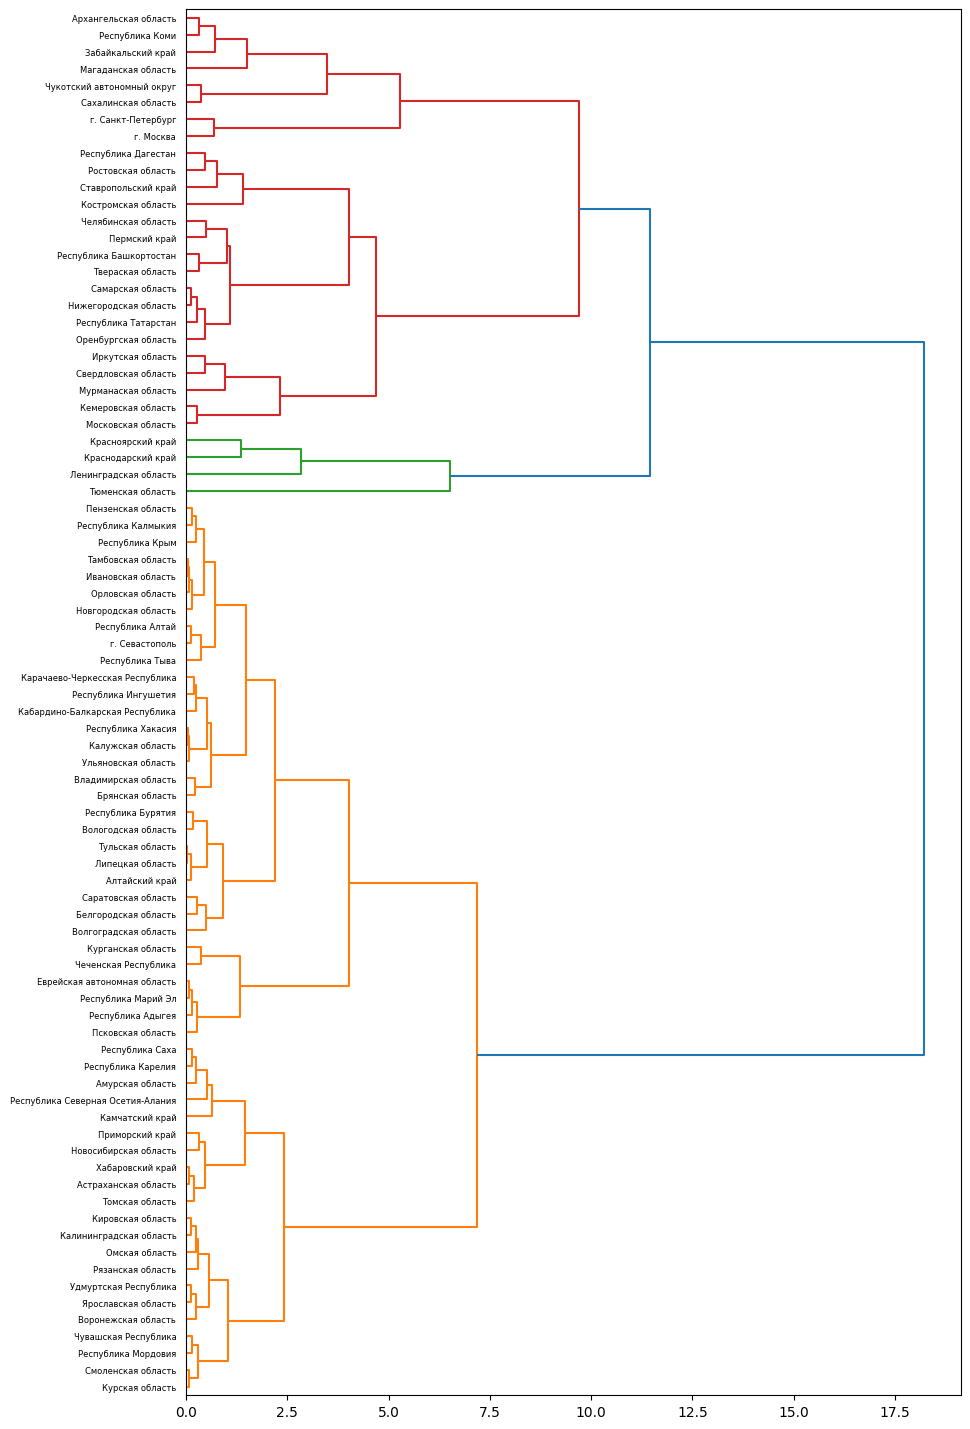

In [105]:
Z = linkage(integral_char[["PC1", "PC2"]], method='ward', metric='euclidean')

plt.close()
plt.figure(figsize=(10, 18))
dendrogram(Z, color_threshold=10, orientation="right", labels = integral_char.index)
plt.savefig("dendro.png")

In [106]:
integral_char["class"] = sk_ac_pred_res
integral_char.head()
integral_char.to_excel("clusters.xlsx")

In [107]:
integral_char.groupby("class").agg(["count", "mean"])

PC1             PC2          
      count      mean count      mean
class                                
0        21  2.069485    21  0.390297
1        53 -0.877684    53 -0.580276
2         8  0.382259     8  2.819801

In [176]:
integral_char["class"] = sk_ac_pred_res
integral_char.head()
integral_char.to_excel("clusters.xlsx")

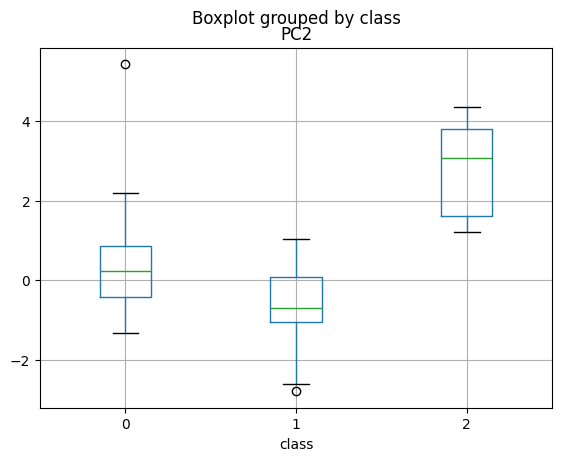

In [179]:
plt.close()
integral_char.boxplot(column="PC2", by = "class")
plt.savefig("pc2_clust_boxs.png")

<Axes: title={'center': 'PC1'}, xlabel='class'>

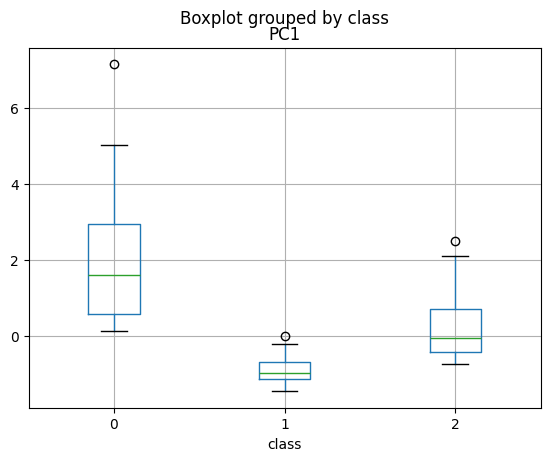

In [180]:
integral_char.boxplot(column="PC1", by = "class")